# BDS / 02 — US T-Bond (`USTBONDTRUSD`): stacked 1-minute days, discovery on H2 (2022–2025)

Protocols: [`BDS 001`](../../../discussions/Bond_Intraday_Seasonality/001_claude_bds01_preregistration.md), amended by [`BDS 002`](../../../discussions/Bond_Intraday_Seasonality/002_claude_bds02_amendment_switches_spikes.md) (contract switches found by Dukascopy's adjustment-break signature; 1-minute price spikes screened out).

Every trading day is laid on top of the others by minute of day, in two clocks (`NY`: 17:00→17:00 New York; `UTC`: 00:00→24:00), and every interval (start every 5 minutes, 15–240 minutes long: 2,704 tests) is tested for a non-zero mean. Its frozen candidates are confirmed on H1 (backward) in `03_cross_confirmation.ipynb`.

| Filter | Condition |
|---|---|
| D1 | Benjamini–Hochberg over this symbol's 2,704 tests, q ≤ 0.05 |
| D2 | same sign in ≥ 75% of counted years (3 of 4, or 3 of 3) |
| D3 | \|mean\| > futures-equivalent cost (one tick of the future + 0.70 bp) |
| D0 | D1–D3 count above the 95th percentile of 20 rotated-day placebos |
| reported | Bonferroni over the 3 symbols (\|t\| ≥ 4.52); `D3_cfd` (beats Dukascopy's CFD spread); trimmed mean |

Before scanning, the quarterly **contract switches** (the CFD jumps to the next future's price at the adjustment break) are found and the days containing them dropped, and so are days with an impossible 1-minute price spike (§2).

**Reads 2022–2025 only; 2026 is refused in code.** Writes `02/candidates_frozen.csv`: commit it before running `03_cross_confirmation.ipynb`.

`BDS_SYNTHETIC=1`: offline run on synthetic candles (UST: +4 bp/day injected 08:30–09:30 New York; all: a −60 bp switch every quarter after a 20-minute early stop, a larger +90 bp ordinary weekend gap in each roll window, two 300 bp one-minute spikes, 10 missing files).

In [1]:
SYMBOL = "USTBONDTRUSD"
WINDOW = "H2"

import json, os, sys, tempfile
import datetime as dt
from dataclasses import replace, asdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("BDS_SYNTHETIC") == "1"
if SYNTHETIC:                                   # never touch the real market-data folder in a smoke run
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("BDS_SYNTH_DIR") or tempfile.mkdtemp(prefix="bds_")
    os.environ["BDS_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]
    os.environ.pop("DUKASCOPY_DIR", None)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F
from equity_trading import bond_seasonality as B

cfg = B.BDSConfig()
if SYNTHETIC:
    cfg = replace(cfg, n_placebo=3, n_boot=2_000)
INFO = B.SYMBOLS[SYMBOL]
SHORT = INFO["short"]
POOLED_T = F.bonferroni_t(len(F.intervals(cfg.fx())) * len(B.CLOCKS) * len(B.SYMBOLS))
HOURS = lambda clock, step: ([60 * h for h in range(0, 25, step)], [F.slot_label(clock, 60 * h).split()[1] for h in range(0, 25, step)])
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 120)
OUT = Path.cwd() / ("02_synthetic" if SYNTHETIC else "02"); OUT.mkdir(exist_ok=True)
START, END = B.WINDOWS[WINDOW]
print(f"{SYMBOL} ({INFO['name']}) | window {WINDOW} {START} -> {END} | bond_seasonality {B.BDS_VERSION} | "
      f"synthetic={SYNTHETIC} | pooled Bonferroni |t| {POOLED_T:.2f}")

USTBONDTRUSD (US T-Bond) | window H2 2022-01-01 -> 2025-12-31 | bond_seasonality 0.2.0 | synthetic=False | pooled Bonferroni |t| 4.52


## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    spec = {"USTBONDTRUSD": (120.0, 4.0, 11), "BUNDTREUR": (135.0, 0.0, 12), "UKGILTTRGBP": (99.0, 0.0, 13)}
    for s, (px, drift, seed) in spec.items():
        if not F.candles_root(s).exists():
            B.write_synthetic_bond(base, s, dt.date(2017, 12, 28), dt.date(2025, 12, 31), seed=seed, drift_bps=drift,
                                   price=px, missing=10, weekend_gap_bps=90.0, spikes=("2019-05-15 12:00", "2023-03-08 13:00"))

## 1. Download complete?

Weekday files from the symbol's first file in the window; at least 95% must exist. Sundays are expected only if the symbol is quoted on Sundays. Missing days are dropped from the stack (with the New York day after them, which spans the missing UTC day).

In [3]:
bd = B.load(SYMBOL, WINDOW, cfg)
fs = bd.files
print(f"{SYMBOL}: first file {fs['first_file']} | weekday files {fs['present_weekdays']}/{fs['expected_weekdays']} ({fs['share']:.2%}) | "
      f"quoted on Sundays: {fs['sunday_session']} | missing expected files {len(fs['missing'])}")
if fs["missing"]:
    print("missing (first 40):", [str(d) for d in fs["missing"][:40]])
assert fs["share"] >= cfg.min_file_share, "fewer than 95% of weekday files: download the missing days and rerun"

USTBONDTRUSD: first file 2022-01-02 | weekday files 1043/1043 (100.00%) | quoted on Sundays: True | missing expected files 0


## 2. Contract switches and price spikes

On the adjustment day Dukascopy stops CFD trading 20 minutes before the close and switches the price to the next future during the break. Per quarter, the switch is the largest gap among breaks with that signature (`early_stop`: last quote 15–25 minutes before the regular close; `midday`: a 45–90 minute break inside the session, used in 2018–2019); `method` = `fallback` if the window had no such break and the largest gap was taken.

Chart: every break's |gap| (bps, log scale); red: the switch, orange: an extra switch-sized break also dropped. Then the 1-minute spikes (a move ≥ 100 bps, or ≥ 50 bps reversed by 80% within 5 quoted minutes) and the days dropped per clock, by reason.

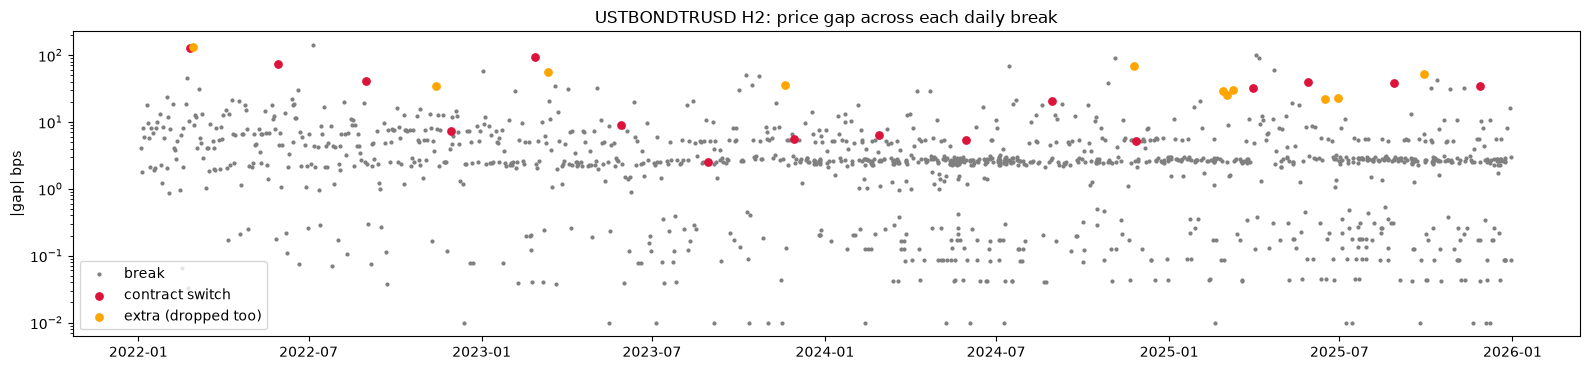

,quarter,before,after,break_minutes,gap_bps,ratio,extra,method,signature
0,2022-03,2022-02-24 21:40,2022-02-24 23:00,80,127.29,47.94,False,signature,early_stop
1,2022-03,2022-02-25 21:59,2022-02-27 23:00,2941,132.95,50.08,True,extra,
2,2022-06,2022-05-27 20:38,2022-05-29 22:00,2962,-73.18,27.56,False,signature,early_stop
3,2022-09,2022-08-30 20:39,2022-08-30 22:00,81,-41.09,15.48,False,signature,early_stop
4,2022-12,2022-11-11 21:59,2022-11-13 23:00,2941,-34.06,12.83,True,extra,
5,2022-12,2022-11-28 21:39,2022-11-28 23:00,81,-7.33,2.76,False,signature,early_stop
6,2023-03,2023-02-24 21:38,2023-02-26 23:00,2962,92.73,34.93,False,signature,early_stop
7,2023-03,2023-03-10 21:59,2023-03-12 22:00,2881,55.92,21.06,True,extra,
8,2023-06,2023-05-26 20:35,2023-05-28 22:00,2965,-8.85,3.33,False,signature,early_stop
9,2023-09,2023-08-29 20:37,2023-08-29 22:00,83,2.56,0.96,False,signature,early_stop


median |gap| over all 1379 breaks: 2.65 bps | switch methods: {'signature': 15, 'fallback': 1}
1-minute price spikes flagged: 10 on 10 days


,ts,move_bps,reverted_bps,kind
0,2022-10-13 12:30,-103.8,-30.3,large
1,2022-12-13 13:30,104.6,47.2,large
2,2023-01-12 13:30,-80.7,69.8,spike
3,2023-02-14 13:30,-53.7,68.4,spike
4,2024-02-13 13:30,-100.7,-43.3,large
5,2024-04-10 12:34,-134.7,-5.1,large
6,2024-06-07 12:30,-118.2,-34.4,large
7,2024-06-12 12:30,108.1,2.8,large
8,2024-08-02 12:30,115.1,-22.3,large
9,2025-04-09 17:19,-55.2,97.4,spike


,clock,days built,missing file,low coverage,contract switch,price spike,kept
0,NY,1043,0,32,50,10,951
1,UTC,1043,0,32,26,10,975


In [4]:
br = B.break_gaps(bd.minutes, cfg.break_minutes)
fig, ax = plt.subplots(figsize=(16, 3.8))
ax.scatter(br["after"], br["gap_bps"].abs().clip(lower=1e-2), s=4, color="grey", label="break")
if len(bd.rolls):
    m = bd.rolls[~bd.rolls["extra"]]; x = bd.rolls[bd.rolls["extra"]]
    ax.scatter(m["after"], m["gap_bps"].abs(), s=28, color="crimson", label="contract switch")
    ax.scatter(x["after"], x["gap_bps"].abs(), s=28, color="orange", label="extra (dropped too)")
ax.set_yscale("log"); ax.set_ylabel("|gap| bps"); ax.legend(); ax.set_title(f"{SYMBOL} {WINDOW}: price gap across each daily break")
plt.tight_layout(); plt.savefig(OUT / "02_breaks.png", dpi=110); plt.show()
r = bd.rolls.copy()
if len(r):
    r["before"] = r["before"].dt.strftime("%Y-%m-%d %H:%M"); r["after"] = r["after"].dt.strftime("%Y-%m-%d %H:%M")
display(r.round(2)); r.to_csv(OUT / "02_contract_switches.csv", index=False)
print(f"median |gap| over all {len(br)} breaks: {br['gap_bps'].abs().median():.2f} bps | switch methods: "
      f"{bd.rolls.loc[~bd.rolls['extra'], 'method'].value_counts().to_dict() if len(bd.rolls) else {}}")
sp = bd.spikes.copy()
print(f"1-minute price spikes flagged: {len(sp)} on {sp['ts'].dt.date.nunique() if len(sp) else 0} days")
if len(sp):
    display(sp.assign(ts=sp["ts"].dt.strftime("%Y-%m-%d %H:%M")).round(1).head(40))
sp.to_csv(OUT / "02_spikes.csv", index=False)
display(bd.drops)

## 3. Stack the days

In [5]:
panels = {(SYMBOL, c): bd.panels[c] for c in B.CLOCKS}
N_YEARS, NEED = B.d2_needed(bd.panels, cfg)
display(pd.DataFrame([{"clock": c, "days": len(p.dates), "first": str(p.dates[0]), "last": str(p.dates[-1]),
                       "counted years": ", ".join(map(str, B.counted_years(p, cfg))),
                       "median quoted minutes": int(np.median(p.coverage) * F.SLOTS),
                       "median CFD spread bps": float(np.median(p.spread_bps()[:, np.median(p.spread_bps(), axis=0) < 50])),
                       "futures cost bps": B.cost_bps(p, cfg), "price first": float(p.mid[0, 0]), "price last": float(p.mid[-1, -1])}
                      for c, p in bd.panels.items()]).round(3))
print(f"D2: same sign in >= {NEED} of {N_YEARS} counted years")

,clock,days,first,last,counted years,median quoted minutes,median CFD spread bps,futures cost bps,price first,price last
0,NY,951,2022-01-03,2025-12-31,"2022, 2023, 2024, 2025",848,3.962,3.293,159.985,115.264
1,UTC,975,2022-01-03,2025-12-31,"2022, 2023, 2024, 2025",839,3.963,3.295,160.078,115.264


D2: same sign in >= 3 of 4 counted years


## 4. The stacked day

Top: mean cumulative mid return from the day start (bps) ± 2 standard errors; grey: hours where the median spread is above twice its daily median (closed or thin). Bottom: the same path for each year. Real structure shows up in most years at the same time of day.

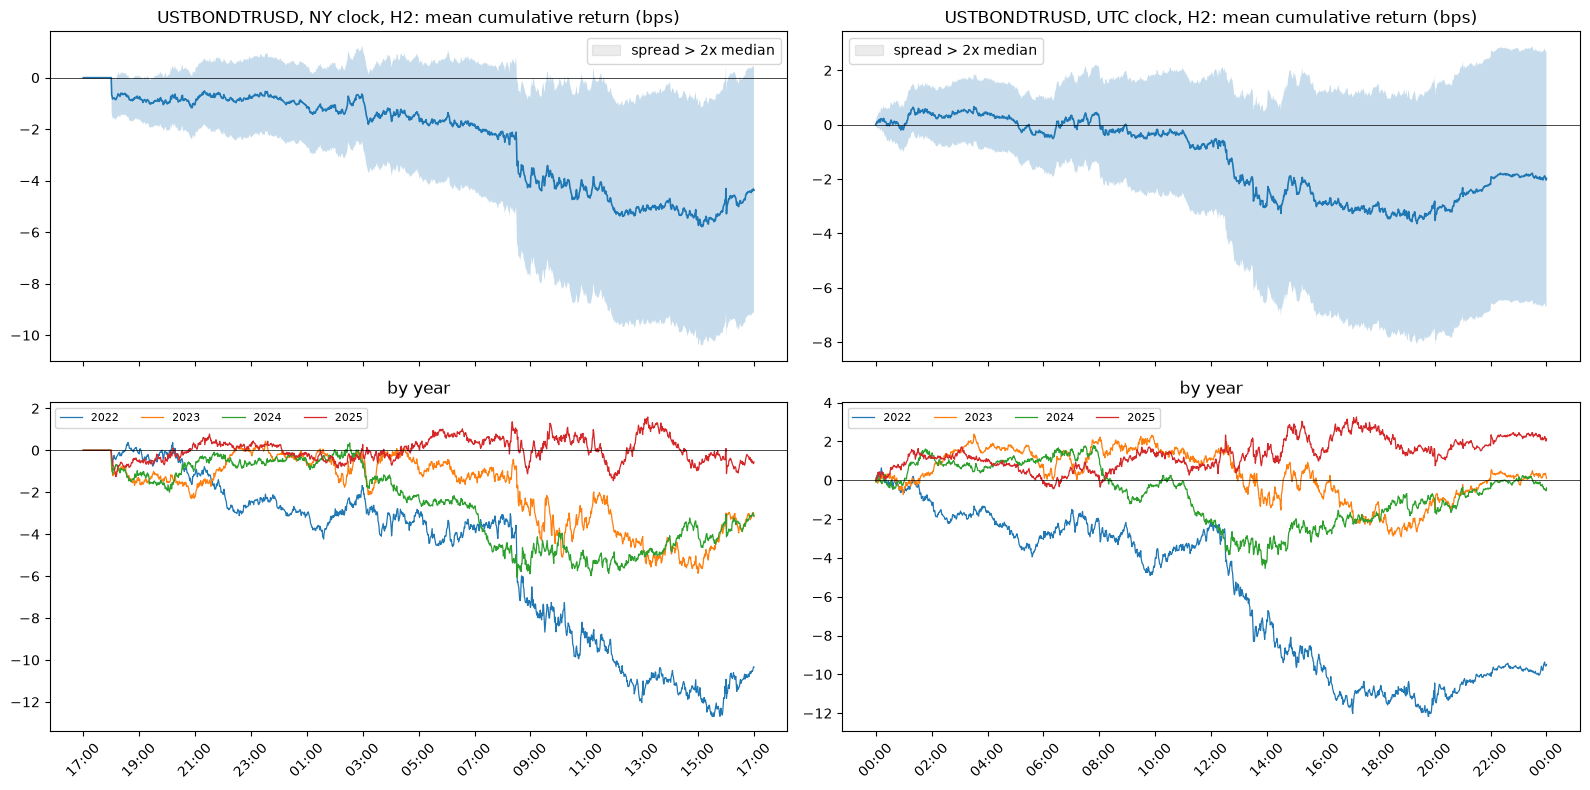

In [6]:
prof = {c: F.profile(bd.panels[c]) for c in B.CLOCKS}
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex="col")
for j, clock in enumerate(B.CLOCKS):
    pr, x = prof[clock], prof[clock].index / 60
    ax = axes[0, j]
    ax.plot(x, pr["cum_mean_bps"], lw=1.2)
    ax.fill_between(x, pr["cum_mean_bps"] - 2 * pr["cum_se_bps"], pr["cum_mean_bps"] + 2 * pr["cum_se_bps"], alpha=0.25)
    wide = (pr["spread_bps"] > 2 * pr["spread_bps"].median()).to_numpy()
    ax.fill_between(x, 0, 1, where=wide, transform=ax.get_xaxis_transform(), color="grey", alpha=0.15, label="spread > 2x median")
    ax.axhline(0, color="black", lw=0.5); ax.set_title(f"{SYMBOL}, {clock} clock, {WINDOW}: mean cumulative return (bps)"); ax.legend()
    yp = F.yearly_profiles(bd.panels[clock])
    for y in yp.columns:
        axes[1, j].plot(x, yp[y], lw=0.9, label=str(y))
    axes[1, j].axhline(0, color="black", lw=0.5); axes[1, j].legend(ncol=4, fontsize=8); axes[1, j].set_title("by year")
    t, l = HOURS(clock, 2)
    axes[1, j].set_xticks(np.array(t) / 60); axes[1, j].set_xticklabels(l, rotation=45)
plt.tight_layout(); plt.savefig(OUT / "04_stacked_day.png", dpi=110); plt.show()
pd.DataFrame({c: prof[c]["cum_mean_bps"] for c in B.CLOCKS}).to_csv(OUT / "04_profile_cum_mean.csv")

## 5. Activity and cost by minute of day

Mean absolute 1-minute return and median CFD spread (log scale), with the futures tick as a dashed line. Shows when the market is open and where trading is cheap; not a direction signal.

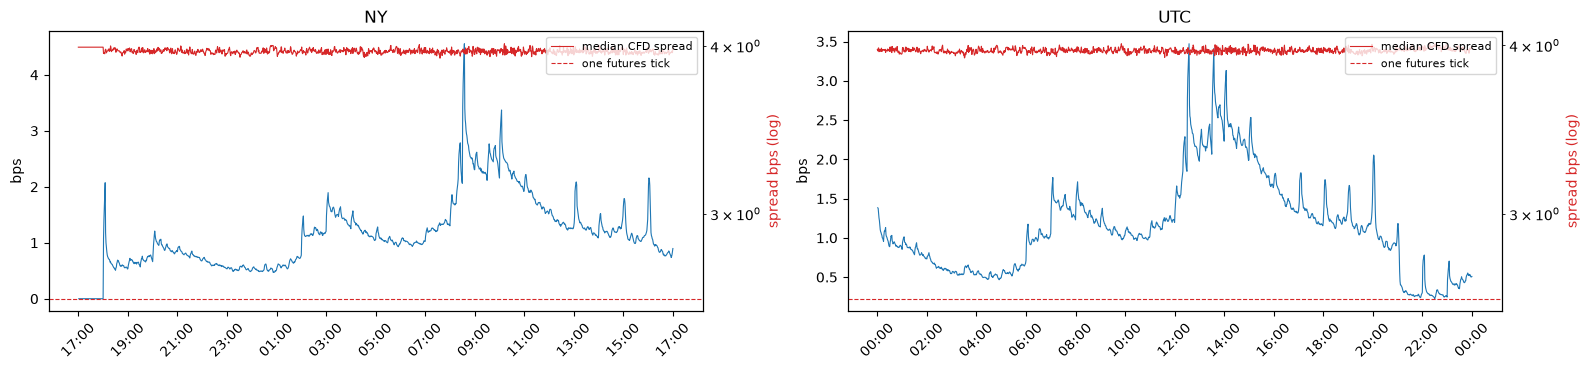

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
for j, clock in enumerate(B.CLOCKS):
    pr, p = prof[clock], bd.panels[clock]
    ax = axes[j]; ax2 = ax.twinx()
    ax.plot(pr.index / 60, pr["abs_ret_bps"].rolling(5, min_periods=1).mean(), lw=0.8, label="mean |1-min return|")
    ax2.plot(pr.index / 60, pr["spread_bps"], lw=0.8, color="C3", label="median CFD spread")
    ax2.axhline(float(B.tick_bps(SYMBOL, np.median(p.mid))), color="C3", ls="--", lw=0.8, label="one futures tick")
    ax2.set_yscale("log"); ax2.legend(loc="upper right", fontsize=8)
    t, l = HOURS(clock, 2); ax.set_xticks(np.array(t) / 60); ax.set_xticklabels(l, rotation=45)
    ax.set_ylabel("bps"); ax2.set_ylabel("spread bps (log)", color="C3"); ax.set_title(clock)
plt.tight_layout(); plt.savefig(OUT / "05_activity.png", dpi=110); plt.show()

## 6. 15-minute blocks: size and consistency

Each bar is one 15-minute block: its t-statistic, coloured by the share of years with the same sign. Dashed: the pooled Bonferroni line. Descriptive; the formal test is §7.

D:\Projects\equity_trading\src\equity_trading\fx_seasonality.py:290: RuntimeWarning: invalid value encountered in divide
  return m, se, m / se


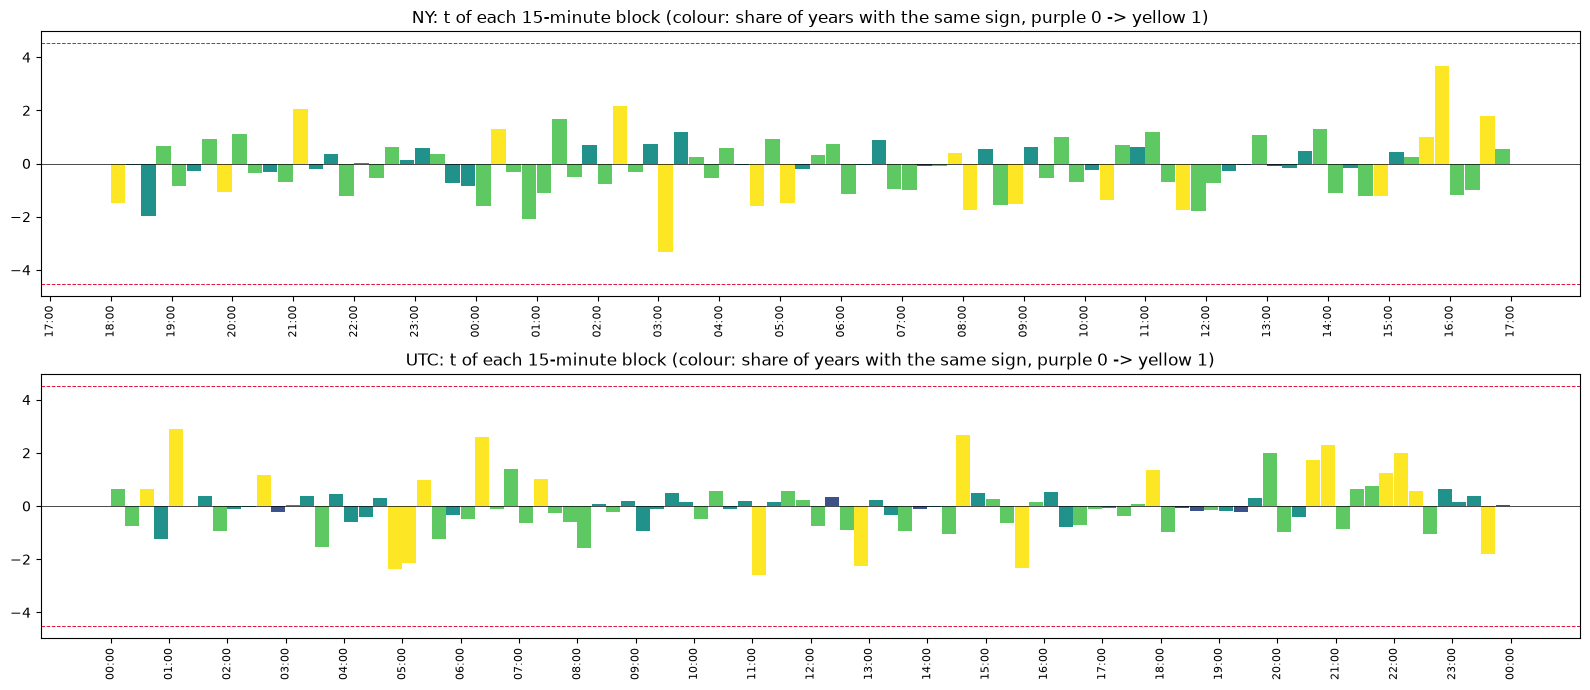

,clock,start,time,mean_bps,t,share_up,years_same_sign,n_years
91,NY,1365,NY 15:45,1.002,3.651,0.531,4,4
40,NY,600,NY 03:00,-0.981,-3.341,0.425,4,4
4,UTC,60,UTC 01:00,0.544,2.881,0.530,4,4
58,UTC,870,UTC 14:30,1.034,2.681,0.531,4,4
44,UTC,660,UTC 11:00,-0.582,-2.605,0.466,4,4
25,UTC,375,UTC 06:15,0.506,2.596,0.508,4,4
19,UTC,285,UTC 04:45,-0.238,-2.370,0.428,4,4
62,UTC,930,UTC 15:30,-0.737,-2.335,0.474,4,4
83,UTC,1245,UTC 20:45,0.482,2.300,0.503,4,4
51,UTC,765,UTC 12:45,-0.836,-2.236,0.497,4,4


In [8]:
bc = {c: F.block_consistency(bd.panels[c], 15) for c in B.CLOCKS}
fig, axes = plt.subplots(2, 1, figsize=(16, 7))
for ax, clock in zip(axes, B.CLOCKS):
    b = bc[clock]
    ax.bar(b["start"] / 60, b["t"], width=0.24, color=plt.cm.viridis(b["years_same_sign"] / b["n_years"]), align="edge")
    for s in (1, -1):
        ax.axhline(s * POOLED_T, color="crimson", ls="--", lw=0.7)
    ax.axhline(0, color="black", lw=0.5)
    t, l = HOURS(clock, 1); ax.set_xticks(np.array(t) / 60); ax.set_xticklabels(l, rotation=90, fontsize=8)
    ax.set_title(f"{clock}: t of each 15-minute block (colour: share of years with the same sign, purple 0 -> yellow 1)")
plt.tight_layout(); plt.savefig(OUT / "06_blocks.png", dpi=110); plt.show()
pd.concat(bc, names=["clock"]).to_csv(OUT / "06_blocks.csv")
display(pd.concat(bc, names=["clock"]).reset_index(level=0).dropna(subset=["t"]).sort_values("t", key=abs, ascending=False).head(15).round(3))

## 7. Interval scan: D1–D3 and the frozen candidates

Map: t-statistic of every interval by start time (x) and length (y); white = closed hours (no test). Black dots: intervals passing D1–D3.

USTBONDTRUSD H2: tests 2,686 | D1 0 | D1+D2 0 | D1+D2+D3 0 | D1+D2+D3_cfd 0 | candidates 0 | pooled-Bonferroni |t| 0


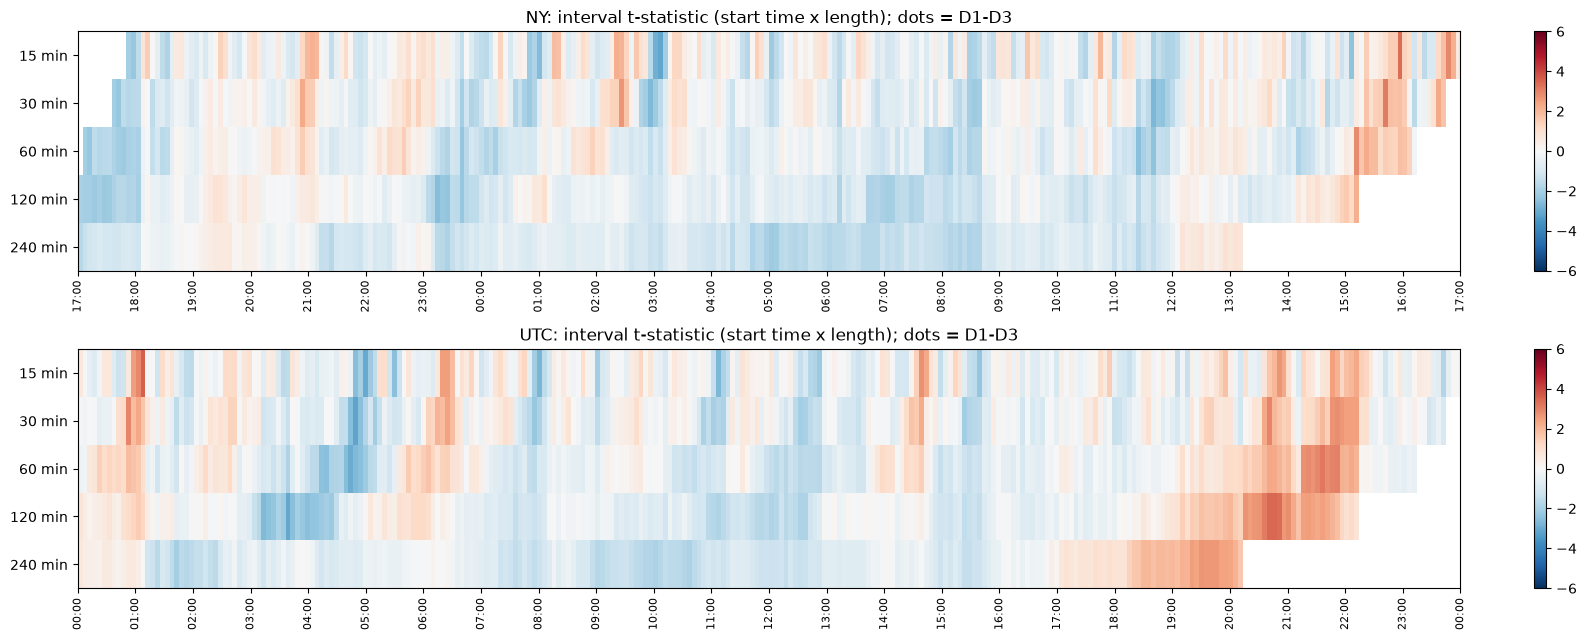

no candidates
frozen: candidates_frozen.csv sha256 7354c3c9758f95d38aefe5ce40a2504436080d2f2b40b357513993f20d0fd522


In [9]:
scan = pd.concat([B.scan_panel(bd.panels[c], cfg) for c in B.CLOCKS], ignore_index=True)
scan, cand = B.select(scan, cfg, NEED, SHORT, WINDOW)
scan["pooled_bonferroni"] = scan["t"].abs() >= POOLED_T
print(f"{SYMBOL} {WINDOW}: tests {int(scan['p'].notna().sum()):,} | D1 {int(scan['D1'].sum())} | D1+D2 {int((scan['D1'] & scan['D2']).sum())} | "
      f"D1+D2+D3 {int(scan['D123'].sum())} | D1+D2+D3_cfd {int((scan['D1'] & scan['D2'] & scan['D3_cfd']).sum())} | "
      f"candidates {len(cand)} | pooled-Bonferroni |t| {int(scan['pooled_bonferroni'].sum())}")
fig, axes = plt.subplots(2, 1, figsize=(16, 6.5))
for ax, clock in zip(axes, B.CLOCKS):
    s = scan[scan["clock"] == clock]
    grid = s.pivot(index="minutes", columns="start", values="t")
    im = ax.imshow(grid.to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-6, vmax=6,
                   extent=[0, 24, len(grid) - 0.5, -0.5], interpolation="nearest")
    hit = s[s["D123"]]
    ax.scatter(hit["start"] / 60, [list(grid.index).index(m) for m in hit["minutes"]], s=6, color="black")
    ax.set_yticks(range(len(grid))); ax.set_yticklabels([f"{m} min" for m in grid.index])
    t, l = HOURS(clock, 1); ax.set_xticks(np.array(t) / 60); ax.set_xticklabels(l, rotation=90, fontsize=8)
    ax.set_title(f"{clock}: interval t-statistic (start time x length); dots = D1-D3")
    fig.colorbar(im, ax=ax, fraction=0.015)
plt.tight_layout(); plt.savefig(OUT / "07_scan_map.png", dpi=110); plt.show()
if len(cand):
    cand["pooled_bonferroni"] = cand["t"].abs() >= POOLED_T
    display(cand[B.CAND_COLS + ["pooled_bonferroni"]].round(3))
else:
    cand = pd.DataFrame(columns=B.CAND_COLS)
    print("no candidates")
scan[scan["D1"]].to_csv(OUT / "07_scan_D1_survivors.csv", index=False)
frozen = OUT / "candidates_frozen.csv"
cand[B.CAND_COLS].to_csv(frozen, index=False, float_format="%.6f")
sha = F.file_sha256(frozen)
print("frozen:", frozen.name, "sha256", sha)

## 8. Robustness of each candidate

Mean, 1%-trimmed mean, median and share of positive days in the trade direction (bps), then the mean by year. A mean carried by a few extreme days (a missed contract switch, a data release) shows a trimmed mean and median far below the mean.

In [10]:
if len(cand):
    rob = B.robustness(bd.panels, cand, cfg)
    display(rob.round(3)); rob.to_csv(OUT / "08_robustness.csv", index=False)
    ym = B.yearly_means(bd.panels, cand)
    display(ym.round(2)); ym.to_csv(OUT / "08_by_year.csv")
else:
    print("no candidates")

no candidates


## 9. Where the candidates sit

In [11]:
if len(cand):
    n = len(cand)
    fig, axes = plt.subplots(int(np.ceil(n / 2)), 2, figsize=(16, 3.2 * np.ceil(n / 2)), squeeze=False)
    for ax, (_, r) in zip(axes.flat, cand.iterrows()):
        pr = prof[r["clock"]]
        ax.plot(pr.index / 60, pr["cum_mean_bps"], lw=1)
        ax.axvspan(r["start"] / 60, r["end"] / 60, color="green" if r["direction"] > 0 else "red", alpha=0.2)
        ax.axhline(0, color="black", lw=0.5)
        ax.set_title(f"{r['id']} {r['start_time']}-{r['end_time'].split()[1]} {'long' if r['direction'] > 0 else 'short'}: "
                     f"{r['mean_bps']:.2f} bp/day, t={r['t']:.1f}, cost {r['cost_bps']:.2f} bp", fontsize=9)
        t, l = HOURS(r["clock"], 2); ax.set_xticks(np.array(t) / 60); ax.set_xticklabels(l, fontsize=8)
    for ax in axes.flat[n:]:
        ax.axis("off")
    plt.tight_layout(); plt.savefig(OUT / "09_candidates.png", dpi=110); plt.show()
else:
    print("no candidates")

no candidates


## 10. D0: rotated-day placebos

Each day's 1-minute returns rotated by a random offset (same returns and daily move, time of day destroyed); the full pipeline rerun 20 times. Takes several minutes.

In [12]:
pl = B.placebo_counts(bd.panels, cfg, NEED)
real = int(scan["D123"].sum())
p95 = float(np.percentile(pl["D1_D2_D3"], 95))
d0 = "STRUCTURE_FOUND" if real > p95 else "NO_STRUCTURE"
display(pl.describe().loc[["mean", "50%", "max"]])
print(f"{SYMBOL} {WINDOW}: real D1-D3 {real} vs placebo 95th percentile {p95:.1f} -> {d0}")
pl.to_csv(OUT / "10_placebo.csv", index=False)

,run,D1,D1_D2_D3,candidates
mean,9.5,0.0,0.0,0.0
50%,9.5,0.0,0.0,0.0
max,19.0,0.0,0.0,0.0


USTBONDTRUSD H2: real D1-D3 0 vs placebo 95th percentile 0.0 -> NO_STRUCTURE


In [13]:
summary = {"study": "BDS01", "symbol": SYMBOL, "window": WINDOW, "dates": [str(START), str(END)],
           "bds_version": B.BDS_VERSION, "synthetic": SYNTHETIC,
           "files": {k: (str(v) if k == "first_file" else v) for k, v in bd.files.items() if k != "missing"},
           "missing_files": len(bd.files["missing"]), "contract_switches": int((~bd.rolls["extra"]).sum()) if len(bd.rolls) else 0,
           "drops": bd.drops.to_dict(orient="records"), "counted_years": N_YEARS, "d2_needed": NEED,
           "tests": int(scan["p"].notna().sum()), "D1": int(scan["D1"].sum()), "D1_D2": int((scan["D1"] & scan["D2"]).sum()),
           "D1_D2_D3": real, "D1_D2_D3_cfd": int((scan["D1"] & scan["D2"] & scan["D3_cfd"]).sum()), "candidates": int(len(cand)),
           "pooled_bonferroni_candidates": int(cand["pooled_bonferroni"].sum()) if len(cand) else 0,
           "placebo_D1_D2_D3": pl["D1_D2_D3"].tolist(), "D0": d0, "candidates_sha256": sha,
           "config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in asdict(cfg).items()}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps({k: summary[k] for k in ("symbol", "window", "D1", "D1_D2", "D1_D2_D3", "D1_D2_D3_cfd", "candidates", "D0")}, indent=2))

{
  "symbol": "USTBONDTRUSD",
  "window": "H2",
  "D1": 0,
  "D1_D2": 0,
  "D1_D2_D3": 0,
  "D1_D2_D3_cfd": 0,
  "candidates": 0,
  "D0": "NO_STRUCTURE"
}
